# Genetic Algorithm Assignment

To ensure that everything runs properly please press the run all button and wait for the outputs. I've reused variables and running cells out of order might mess up the output. The longest running cell is where it generates 15 different solutions for problem_2. Can last up to around 1m. Thanks

### How the report works
I've included markdown text **above** the function which explains what the function does as well as some variables

I've written a quick report which displays some stats for how well each genetic algorithm performed in each of the problems

## 2.1 Task 1 - Implement a Binary Generational GA

---
### random_individual function

Takes an input to define the length of the individual gene. Randomly generates either a 1 or 0 and returns the gene

In [765]:
import random

def random_individual(length):
    output = []
    for x in range(0, length):
        output.append(random.randint(0, 1))
    return output
        
print(random_individual(5))

[1, 1, 0, 0, 1]


---
### onemax_fitness & deceptive_fitness functions

Both take a gene as an input and generates a fitness. These functions were predefined for me in lab 3 and so I copied them over. onemax_fitness was the one used in this assigment and just returns the sum of 1s in the gene

In [766]:
def onemax_fitness(genome):
    return sum(genome) # Fitness is simply the count of 1s.

def deceptive_fitness(genome):
    u = sum(genome)       # Unitation (number of 1s)
    L = len(genome)       # Length of genome
    
    if L - u <= 2: # Near the global optimum
        return u
    else:          # Near a less good optimum
        return L - u - 1 
    
gene = random_individual(5)
print("Gene: " + str(gene))
print("onemax_fitness: " + str(onemax_fitness(gene)))
print("deceptive_fitness: " + str(deceptive_fitness(gene)))

Gene: [1, 0, 0, 0, 0]
onemax_fitness: 1
deceptive_fitness: 3


---
### random_population function

Takes a population size and gene length as an input. generates a population of 'pop' size of genes of 'length' size and returns it. 

In [767]:
def random_population(pop, length):
    output = []
    for x in range(0, pop):
        output.append(random_individual(length))

    return output

print(random_population(5, 5))
population = random_population(5, 5)

[[0, 1, 0, 1, 1], [1, 1, 1, 1, 0], [0, 0, 1, 1, 0], [0, 0, 1, 1, 0], [0, 0, 1, 0, 0]]


---
### eval_fitness function

loops through every gene in the population and calculates a fitness for each. fitness value is stored and returned

In [768]:
def eval_fitness():
    output = []
    for gene in population:
        output.append(onemax_fitness(gene))

    return output

print(eval_fitness())
fitness = eval_fitness()

[1, 3, 3, 3, 3]


---
### tournament function

takes a population size and tournament size as an input. randomly selects a tournament size number of genes from the population. then loops through all the genes and selects which gene is **largest**. the **largest** gene is returned

In [769]:
def tournament(pop_size, tour_size):
    random_gene = []

    for num in range(0, tour_size):
        random_gene.append(random.randint(0, pop_size -1))

    maximum = -999
    max_index = 0

    for index in range(0, len(random_gene)):
        if fitness[random_gene[index]] >= maximum:
            maximum = fitness[random_gene[index]]
            max_index = random_gene[index]

    return max_index

population = random_population(5, 4)
fitness = eval_fitness()
print("Population: " + str(population))
print("Fitness: " + str(fitness))
print(tournament(5, 5))

Population: [[1, 0, 1, 1], [1, 0, 1, 1], [0, 1, 1, 1], [0, 1, 1, 1], [1, 1, 1, 0]]
Fitness: [3, 3, 3, 3, 3]
4


---
### neg_tournament function

takes a population size and tournament size as an input. randomly selects a tournament size number of genes from the population. then loops through all the genes and selects which gene is **smallest**. the **smallest** gene is returned

In [770]:
def neg_tournament(pop_size, tour_size):
    random_gene = []
    for num in range(0, tour_size):
        random_gene.append(random.randint(0, pop_size-1))

    minimum = 999
    min_index = 0

    for index in range(0, len(random_gene)):
        if fitness[random_gene[index]] <= minimum:
            minimum = fitness[random_gene[index]]
            min_index = random_gene[index]

    return min_index

population = random_population(5, 5)
fitness = eval_fitness()
print("Population: " + str(population))
print("Fitness: " + str(fitness))
print(neg_tournament(5, 3))

Population: [[1, 0, 1, 0, 1], [1, 1, 1, 0, 1], [0, 1, 1, 0, 1], [1, 0, 0, 1, 0], [0, 1, 0, 0, 0]]
Fitness: [3, 4, 3, 2, 1]
4


---
### muate function

takes an index as an input. the index is gene that is used as a parent. each bit is given a chance to flip. chance determined by the mutation_rate variable. the changed gene is then returned

In [771]:
def mutate(index):
    global mutation_rate

    parent = population[index]
    offspring = []
    for bit in parent:
        if random.random() < mutation_rate:
            offspring.append(1 - bit)
        else:
            offspring.append(bit)
    return offspring

mutation_rate = 1/5
index = tournament(5, 2)
print("Parent:    " + str(population[index]))
print("Offspring: " + str(mutate(index)))

Parent:    [1, 1, 1, 0, 1]
Offspring: [1, 1, 1, 0, 1]


---
### crossover function

takes two indexs as an input. both of these indexes are parent genes. a crosspoint is randomly decided. The front part of the first parent is combined with the back part of the second parent. this creates and new gene which is returned 

In [772]:
def crossover(index1, index2):
    # select parents
    parent1 = population[index1]
    parent2 = population[index2]
    
    # select crossover point
    crossPoint = random.randint(1, len(parent1) -1)
    # print(crossPoint)
    
    # perform crossover
    offspring = parent1[:crossPoint]
    offspring += parent2[crossPoint:]
    
    return offspring

index1 = tournament(5, 2)
index2 = tournament(5, 2)

print("Parent 1 : " + str(population[index1]))
print("Parent 2 : " + str(population[index2]))
print("Offspring: " + str(crossover(index1, index2)))

Parent 1 : [1, 1, 1, 0, 1]
Parent 2 : [0, 1, 1, 0, 1]
Offspring: [1, 1, 1, 0, 1]


---
### check  functions

has the gene size as an input. this function loops through all the fitness values and checks if it has reached the max. the index of that gene is returned. if none of the fitness values have reached max then 0 is returned 

In [773]:
def check(N):
    for gene in range(0, len(population)):
        if onemax_fitness(population[gene]) == N:
            return gene + 1
    return 0

---

In [774]:
# BINARY GENERATIONAL GA
N = 5
M = 5
mutation_rate = 1/N
crossover_rate = random.random()
population = random_population(M, N)
fitness = eval_fitness()
generation = 0

while not check(N):
    index = tournament(M, 2)
    offspring = None
    crossover_rate = random.random()

    if crossover_rate < 1/2:
        offspring = mutate(index)
        print("MUTATE")
    else:
        offspring = crossover(index, tournament(M, 2))
        print("CROSSOVER")

    population[neg_tournament(M, 2)] = offspring
    fitness = eval_fitness()
    generation += 1

    print("Generation: " + str(generation))
    print("Offspring: " + str(offspring))
    print("Fitness: " + str(fitness))
    print("Population: " + str(population))

print("Gene: " + str(population[check(N) - 1]))

MUTATE
Generation: 1
Offspring: [0, 0, 1, 1, 0]
Fitness: [3, 2, 2, 2, 2]
Population: [[0, 0, 1, 1, 1], [0, 1, 1, 0, 0], [0, 1, 0, 1, 0], [0, 0, 1, 1, 0], [0, 0, 1, 1, 0]]
CROSSOVER
Generation: 2
Offspring: [0, 1, 1, 1, 0]
Fitness: [3, 2, 3, 2, 2]
Population: [[0, 0, 1, 1, 1], [0, 1, 1, 0, 0], [0, 1, 1, 1, 0], [0, 0, 1, 1, 0], [0, 0, 1, 1, 0]]
CROSSOVER
Generation: 3
Offspring: [0, 0, 1, 1, 0]
Fitness: [3, 2, 3, 2, 2]
Population: [[0, 0, 1, 1, 1], [0, 1, 1, 0, 0], [0, 1, 1, 1, 0], [0, 0, 1, 1, 0], [0, 0, 1, 1, 0]]
CROSSOVER
Generation: 4
Offspring: [0, 0, 1, 1, 0]
Fitness: [3, 2, 3, 2, 2]
Population: [[0, 0, 1, 1, 1], [0, 1, 1, 0, 0], [0, 1, 1, 1, 0], [0, 0, 1, 1, 0], [0, 0, 1, 1, 0]]
CROSSOVER
Generation: 5
Offspring: [0, 1, 1, 0, 0]
Fitness: [3, 2, 2, 2, 2]
Population: [[0, 0, 1, 1, 1], [0, 1, 1, 0, 0], [0, 1, 1, 0, 0], [0, 0, 1, 1, 0], [0, 0, 1, 1, 0]]
MUTATE
Generation: 6
Offspring: [0, 0, 1, 0, 0]
Fitness: [3, 2, 1, 2, 2]
Population: [[0, 0, 1, 1, 1], [0, 1, 1, 0, 0], [0, 0, 1, 0, 

## 2.2 Task 2 - Use your GA to Evolve Sequences of Integers

---
### phenotype function

takes a gene as an input and turns the gene into an integer using binary addition and returns the integer

𝐼 = 𝑏1 + 2×𝑏2 + 4×𝑏3 + 8×𝑏4

In [775]:
def phenotype(gene): #BINARY
    output = 0
    bit = 1

    for num in range(0, len(gene)):
        output += gene[num] * bit
        bit *= 2

    return output


gene = random_individual(4)
print("Gene: " + str(gene))
print(phenotype(gene))

Gene: [1, 0, 0, 1]
9


---
### phenotype_weird function

take a gene as an input and sums all the 1 bits to calcualte an integer which is returned

𝐼 = 𝑏1 + 𝑏2 + ... + 𝑏15

In [776]:
def phenotype_weird(gene): #NON_POSITIONAL BINARY
    output = 0
    for num in gene:
        output += num
    return output

gene = random_individual(15)
print("Gene: " + str(gene))
print(phenotype_weird(gene))


Gene: [1, 0, 0, 0, 1, 1, 1, 1, 1, 1, 0, 0, 1, 0, 0]
8


---
### eval_fitness_pheno function

loops through every gene in the population and calculates the integer value for each. integer is stored and returned

In [777]:
def eval_fitness_pheno(): # 15-MAX
    output = []
    for gene in population:
        output.append(phenotype(gene))
    
    return output


population = random_population(5, 4)
print("Population: " + str(population))
print("Phenotype: " + str(eval_fitness_pheno()))

Population: [[1, 0, 0, 0], [1, 1, 1, 1], [0, 0, 0, 1], [1, 1, 1, 0], [1, 0, 1, 1]]
Phenotype: [1, 15, 8, 7, 13]


---
### soft_eval_fitness_pheno function

has an array of fitness values as an input. loops through all the values and finds the mean value. the mean value is then returned


In [778]:
def soft_eval_fitness_pheno(fitness):
    sum = 0
    for num in fitness:
        sum += num
    
    return sum / len(fitness)

population = random_population(5, 4)
fitness = eval_fitness_pheno()
print("Population: " + str(population))
print("Fitness: " + str(fitness))
print("Soft Phenotype: " + str(soft_eval_fitness_pheno(fitness)))

Population: [[0, 1, 1, 1], [1, 1, 1, 0], [0, 1, 1, 0], [1, 1, 0, 0], [0, 0, 0, 1]]
Fitness: [14, 7, 6, 3, 8]
Soft Phenotype: 7.6


---
### check_pheno function

loops through all the fitness values and checks if it has reached the max. the index of that gene is returned. if none of the fitness values have reached max then 0 is returned 

In [779]:
def check_pheno():
    for gene in range(0, len(population)):
        if phenotype(population[gene]) == 15:
            return gene + 1
    return 0 

## 2.3 Task 3 - Tune the GA and solve 15-max and soft-15-max problems

### 15-Max Problem

In [780]:
# 15-MAX GA
N = 4
M = 5
mutation_rate = 1/N
crossover_rate = random.random()
population = random_population(M, N)
fitness = eval_fitness_pheno()
generation = 0

while not check_pheno():
    index = tournament(M, 3)
    offspring = None
    crossover_rate = random.random()

    if crossover_rate < 1/2:
        offspring = mutate(index)
        print("MUTATE")
    else:
        offspring = crossover(index, tournament(M, 3))
        print("CROSSOVER")

    population[neg_tournament(M, 3)] = offspring
    fitness = eval_fitness_pheno()
    generation += 1

    print("Generation: " + str(generation))
    print("Offspring: " + str(offspring))
    print("Fitness: " + str(fitness))
    print("Population: " + str(population))

print("Gene: " + str(population[check_pheno() - 1]))

CROSSOVER
Generation: 1
Offspring: [0, 0, 1, 1]
Fitness: [6, 7, 12, 12, 11]
Population: [[0, 1, 1, 0], [1, 1, 1, 0], [0, 0, 1, 1], [0, 0, 1, 1], [1, 1, 0, 1]]
CROSSOVER
Generation: 2
Offspring: [0, 0, 1, 1]
Fitness: [6, 12, 12, 12, 11]
Population: [[0, 1, 1, 0], [0, 0, 1, 1], [0, 0, 1, 1], [0, 0, 1, 1], [1, 1, 0, 1]]
CROSSOVER
Generation: 3
Offspring: [0, 0, 1, 1]
Fitness: [12, 12, 12, 12, 11]
Population: [[0, 0, 1, 1], [0, 0, 1, 1], [0, 0, 1, 1], [0, 0, 1, 1], [1, 1, 0, 1]]
MUTATE
Generation: 4
Offspring: [0, 1, 1, 1]
Fitness: [12, 12, 12, 14, 11]
Population: [[0, 0, 1, 1], [0, 0, 1, 1], [0, 0, 1, 1], [0, 1, 1, 1], [1, 1, 0, 1]]
CROSSOVER
Generation: 5
Offspring: [0, 1, 1, 1]
Fitness: [12, 14, 12, 14, 11]
Population: [[0, 0, 1, 1], [0, 1, 1, 1], [0, 0, 1, 1], [0, 1, 1, 1], [1, 1, 0, 1]]
MUTATE
Generation: 6
Offspring: [1, 0, 1, 1]
Fitness: [12, 14, 12, 14, 13]
Population: [[0, 0, 1, 1], [0, 1, 1, 1], [0, 0, 1, 1], [0, 1, 1, 1], [1, 0, 1, 1]]
MUTATE
Generation: 7
Offspring: [0, 0, 0, 0

### Soft-15-Max Problem

In [781]:
# SOFT 15-MAX GA
N = 4
M = 5
mutation_rate = 1/N
crossover_rate = random.random()
population = random_population(M, N)
fitness = eval_fitness_pheno()
generation = 0

while not soft_eval_fitness_pheno(fitness) == 15:
    index = tournament(M, 3)
    offspring = None
    crossover_rate = random.random()

    if crossover_rate < 1/2:
        offspring = mutate(index)
        print("MUTATE")
    else:
        offspring = crossover(index, tournament(M, 3))
        print("CROSSOVER")

    population[neg_tournament(M, 3)] = offspring
    fitness = eval_fitness_pheno()
    generation += 1

    print("Generation: " + str(generation))
    print("Offspring: " + str(offspring))
    print("Fitness: " + str(fitness))
    print("SOFT FITNESS: " + str(soft_eval_fitness_pheno(fitness)))
    print("Population: " + str(population))

print("FINAL POPULATION: " + str(population))

MUTATE
Generation: 1
Offspring: [1, 0, 1, 1]
Fitness: [13, 13, 5, 9, 7]
SOFT FITNESS: 9.4
Population: [[1, 0, 1, 1], [1, 0, 1, 1], [1, 0, 1, 0], [1, 0, 0, 1], [1, 1, 1, 0]]
MUTATE
Generation: 2
Offspring: [1, 0, 1, 1]
Fitness: [13, 13, 13, 9, 7]
SOFT FITNESS: 11.0
Population: [[1, 0, 1, 1], [1, 0, 1, 1], [1, 0, 1, 1], [1, 0, 0, 1], [1, 1, 1, 0]]
MUTATE
Generation: 3
Offspring: [1, 0, 1, 1]
Fitness: [13, 13, 13, 9, 7]
SOFT FITNESS: 11.0
Population: [[1, 0, 1, 1], [1, 0, 1, 1], [1, 0, 1, 1], [1, 0, 0, 1], [1, 1, 1, 0]]
MUTATE
Generation: 4
Offspring: [0, 1, 1, 1]
Fitness: [13, 14, 13, 9, 7]
SOFT FITNESS: 11.2
Population: [[1, 0, 1, 1], [0, 1, 1, 1], [1, 0, 1, 1], [1, 0, 0, 1], [1, 1, 1, 0]]
CROSSOVER
Generation: 5
Offspring: [1, 0, 1, 1]
Fitness: [13, 14, 13, 9, 7]
SOFT FITNESS: 11.2
Population: [[1, 0, 1, 1], [0, 1, 1, 1], [1, 0, 1, 1], [1, 0, 0, 1], [1, 1, 1, 0]]
MUTATE
Generation: 6
Offspring: [1, 1, 1, 1]
Fitness: [13, 14, 13, 9, 15]
SOFT FITNESS: 12.8
Population: [[1, 0, 1, 1], [0, 

---

## 3.1 Task 5 - Representation and Genetic Operators

In [782]:
# Simulator of program execution (GP interpreter) 
# program = sequence of integers 
# x = input variable 
def execute(program, x): 
 
    # A place where to get arguments for operations and  
    # for storing their results 
    stack = []  
 
    # If l = [1,2,3], l.pop() removes 3 from the list and returns it 
    # but if l = [], l.pop() gives an error 
    # Fixing the problem for stack by defining our own pop() 
    def pop(): 
        if not stack: 
            return 0 
        return stack.pop() 
 
    # Main execution loop 
    for instr in program: 
        if instr == 0:   # NOP 
            pass 
        elif instr == 1: # X 
            stack.append(x) 
        elif instr == 2: # + 
            stack.append(pop() + pop()) 
        elif instr == 3: # - 
            stack.append(pop() - pop()) 
        elif instr == 4: # * 
            stack.append(pop() * pop()) 
        elif instr == 5: # 1  
            stack.append(1) 
        elif instr == 6: # -1  
            stack.append(-1) 
        else:            # 0 
            stack.append(0) 
 
    # Returning the very last result appended to stack 
    return pop()

print(execute([5, 1, 2], 3))

4


---
## 3.2 Task 6 - Program Execution and Fitness Functions

---
### to_bytes function

takes gene, number of instructions and byte size as an input. takes the gene and seperates the gene into bytes. bytes get stored and returned

In [783]:
def to_bytes(gene, no_inst, byte_size):
    output = []

    for num in range(0, no_inst):
        # print(num)
        output.append(gene[num * byte_size : (num * byte_size) + byte_size])

    return output

gene = random_individual(5 * 3)
print(gene)
print(to_bytes(gene, 5, 3))

[1, 0, 0, 1, 0, 0, 0, 0, 0, 1, 0, 0, 1, 1, 1]
[[1, 0, 0], [1, 0, 0], [0, 0, 0], [1, 0, 0], [1, 1, 1]]


---
### to_program function

takes number of instructions and byte size as an input. loops through all genes in the population and sperates them all into bytes. 

In [784]:
def to_program(no_inst, byte_size):

    program = []

    for gene in population:
        program.append(to_bytes(gene, no_inst, byte_size))

    return program

population = random_population(5, 5 *3)
print("Population: " + str(population))
print(to_program(5, 3))

Population: [[0, 0, 1, 0, 1, 1, 0, 0, 0, 0, 0, 0, 0, 1, 0], [0, 1, 0, 1, 1, 1, 1, 0, 1, 0, 0, 0, 1, 1, 0], [1, 1, 1, 1, 0, 1, 0, 0, 1, 0, 0, 1, 1, 0, 0], [0, 1, 0, 1, 0, 1, 0, 1, 1, 1, 0, 0, 0, 1, 1], [0, 0, 0, 0, 1, 1, 1, 1, 1, 0, 0, 1, 0, 0, 1]]
[[[0, 0, 1], [0, 1, 1], [0, 0, 0], [0, 0, 0], [0, 1, 0]], [[0, 1, 0], [1, 1, 1], [1, 0, 1], [0, 0, 0], [1, 1, 0]], [[1, 1, 1], [1, 0, 1], [0, 0, 1], [0, 0, 1], [1, 0, 0]], [[0, 1, 0], [1, 0, 1], [0, 1, 1], [1, 0, 0], [0, 1, 1]], [[0, 0, 0], [0, 1, 1], [1, 1, 1], [0, 0, 1], [0, 0, 1]]]


---
### program_phenotype function

takes the population of bytes as an input. loops through all the bytes in the population and converts them to integers. integers are stored and returned

In [785]:
def program_phenotype(program):
    output = []

    for gene in program:

        instruction = []

        for num in gene:
            instruction.append(phenotype(num))

        output.append(instruction)

    return output

population = random_population(5, 5 *3)
program = to_program(5, 3)
print("Population: " + str(population))
print(program_phenotype(program))

Population: [[0, 1, 0, 1, 0, 1, 0, 1, 1, 1, 1, 0, 0, 1, 1], [1, 0, 0, 1, 1, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0], [0, 0, 1, 1, 0, 0, 0, 0, 0, 0, 0, 0, 1, 1, 1], [0, 0, 0, 0, 0, 1, 1, 1, 0, 1, 1, 1, 1, 0, 0], [1, 1, 1, 0, 0, 0, 1, 1, 1, 0, 1, 1, 0, 1, 1]]
[[2, 5, 6, 3, 6], [1, 3, 1, 0, 0], [4, 1, 0, 0, 7], [0, 4, 3, 7, 1], [7, 0, 7, 6, 6]]


---
### execute_program function

takes the list of integers and the program input as an input. it loops through all the list of integers and combined with the program input it runs it through the execute function given and results are stored and returned

In [786]:
def execute_program(instruction, program_input):
    output = []

    for inst in instruction:
        output.append(execute(inst, program_input))

    return output

population = random_population(5, 5*3)
program = to_program(5, 3)
instructions = program_phenotype(program)

print("Population: " + str(population))
print("Instructions: " + str(instructions))
print(execute_program(instructions, -1))


Population: [[0, 0, 1, 1, 0, 1, 0, 0, 1, 1, 0, 1, 1, 0, 1], [0, 1, 0, 0, 1, 0, 1, 0, 0, 1, 1, 0, 0, 1, 0], [1, 0, 1, 1, 1, 0, 1, 1, 1, 0, 0, 1, 0, 1, 1], [0, 0, 1, 0, 1, 0, 1, 0, 1, 1, 1, 1, 0, 0, 1], [1, 1, 1, 0, 0, 0, 1, 1, 0, 0, 1, 1, 0, 0, 1]]
Instructions: [[4, 5, 4, 5, 5], [2, 2, 1, 3, 2], [5, 3, 7, 4, 6], [4, 2, 5, 7, 4], [7, 0, 3, 6, 4]]
[1, -1, -1, 0, 0]


---
### best function

takes list of fitness values and the program input. if the input variable is -1 then it finds the **smallest** value from the whole of fitnesses. if the input variable is 1 then it find the **largest** value from the whole of fitnesses. The corresponding best value is then returned. This is used to find the best fit gene through each generation

In [787]:
def best(fitness, input_variable):
    bool = input_variable + 1

    best_num = fitness[0]
    best_index = 0

    for index in range(0, len(fitness)):

        if not bool: # -1
            if fitness[index] <= best_num:
                best_num = fitness[index]
                best_index = index
        else: # 1
            if fitness[index] >= best_num:
                best_num = fitness[index]
                best_index = index
    
    return best_index

input_variable = -1
population = random_population(5, 5*3)
program = to_program(5, 3)
instructions = program_phenotype(program)
fitness = execute_program(instructions, input_variable)

print("Fitness: " + str(fitness))
print(best(fitness, input_variable))

Fitness: [0, 0, 1, -1, 1]
3


### Problem 1

In [788]:
def generate_offspring(crossover_rate, index, input_variable, tournament_size):
    offspring = None

    if crossover_rate < 5/8:
        offspring = mutate(index)
        # print("MUTATE")
    else:
        # print("CROSSOVER")

        bool = input_variable + 1

        if not bool: # -1
            offspring = crossover(index, neg_tournament(M, tournament_size))
        else: # 1
            offspring = crossover(index, tournament(M, tournament_size))
        
    return offspring

The fitness values are simply the result of the execute function. With input variable being -1 will favour larger **negative** values while an input variable of 1 will favour larger **positive** values.

In [789]:
# PROBLEM 1 

def problem_1(input_variable):

    best_fitness = 0
    best_gene = None
    best_instruction = None

    best_of_best = []

    for gen in range(0, generation_limit):
        offspring = None
        crossover_rate = random.random()

        bool = input_variable + 1

        if not bool: # -1
            index = neg_tournament(M, T)
            offspring = generate_offspring(crossover_rate, index, input_variable, T)
            population[tournament(M, T)] = offspring
        else: # 1
            index = tournament(M, T)
            offspring = generate_offspring(crossover_rate, index, input_variable, T)
            population[neg_tournament(M, T)] = offspring

        program = to_program(no_inst, byte_size)
        instructions = program_phenotype(program)
        fitness = execute_program(instructions, input_variable)


        # STORE BEST VALUES FOUND SO FAR
        best_index = best(fitness, input_variable)

        if not bool and fitness[best_index] < best_fitness: # -1
            best_fitness = fitness[best_index]
            best_gene = population[best_index]
            best_instruction = instructions[best_index]
        if bool and fitness[best_index] > best_fitness: # 1
            best_fitness = fitness[best_index]
            best_gene = population[best_index]
            best_instruction = instructions[best_index]

        
        best_of_best.append(best_fitness)
        # print("======= Generation: " + str(gen) + " ==========")
        # print("Offspring: " + str(offspring))
        # print("Fitness: " + str(fitness))
        # print("Population: " + str(population))
        # print("Instructions: " + str(instructions))
    
    # print("============== BEST VALUES FOUND: ==============")
    # print("Best Fitness: " + str(best_fitness))
    # print("Best Gene: " + str(best_gene))
    # print("Best Instructions: " + str(best_instruction))

    return best_of_best

byte_size = 3 # Bits
no_inst = 20 # No of Instructions

N = no_inst * byte_size  # Gene Length
M = 5 # Population Size
T = 4 # Tournament Size

mutation_rate = 3/N
crossover_rate = random.random()
population = random_population(M, N)
program = to_program(no_inst, byte_size)
instructions = program_phenotype(program)
fitness = execute_program(instructions, 1)
generation_limit = 10000

problem_1(1)
problem_1(-1)

[-1,
 -1,
 -1,
 -1,
 -1,
 -1,
 -1,
 -1,
 -3,
 -3,
 -3,
 -3,
 -3,
 -3,
 -3,
 -3,
 -3,
 -3,
 -3,
 -3,
 -3,
 -3,
 -3,
 -3,
 -3,
 -3,
 -3,
 -3,
 -3,
 -3,
 -3,
 -3,
 -3,
 -3,
 -3,
 -3,
 -3,
 -3,
 -3,
 -3,
 -3,
 -3,
 -3,
 -3,
 -3,
 -3,
 -3,
 -3,
 -3,
 -3,
 -3,
 -3,
 -3,
 -3,
 -3,
 -3,
 -3,
 -3,
 -3,
 -3,
 -3,
 -3,
 -3,
 -3,
 -3,
 -3,
 -3,
 -3,
 -3,
 -3,
 -3,
 -3,
 -3,
 -3,
 -3,
 -3,
 -3,
 -3,
 -3,
 -3,
 -3,
 -3,
 -3,
 -3,
 -3,
 -3,
 -3,
 -3,
 -3,
 -3,
 -3,
 -3,
 -3,
 -3,
 -3,
 -3,
 -3,
 -3,
 -3,
 -3,
 -3,
 -3,
 -3,
 -3,
 -3,
 -3,
 -3,
 -3,
 -3,
 -3,
 -3,
 -3,
 -3,
 -3,
 -3,
 -3,
 -3,
 -3,
 -3,
 -3,
 -3,
 -3,
 -3,
 -3,
 -3,
 -3,
 -3,
 -3,
 -3,
 -3,
 -3,
 -3,
 -3,
 -3,
 -3,
 -3,
 -3,
 -3,
 -3,
 -3,
 -3,
 -3,
 -3,
 -3,
 -3,
 -3,
 -3,
 -3,
 -3,
 -3,
 -3,
 -3,
 -3,
 -3,
 -3,
 -3,
 -3,
 -3,
 -3,
 -3,
 -3,
 -3,
 -3,
 -3,
 -3,
 -3,
 -3,
 -3,
 -3,
 -3,
 -3,
 -3,
 -3,
 -3,
 -3,
 -3,
 -3,
 -3,
 -3,
 -3,
 -3,
 -3,
 -3,
 -3,
 -3,
 -3,
 -3,
 -3,
 -3,
 -3,
 -3,
 -3,
 -3,
 -3,
 -3,
 -3,
 -3,
 -3,
 -3,
 -3,


20 Instructions:
    mutation rate = 3/N
    M = 5,
    T = 4
    gen_limit = 100000

    ============== BEST VALUES FOUND: ==============
    Best Fitness: 36
    Best Gene: [1, 0, 0, 0, 1, 1, 1, 1, 0, 1, 0, 0, 1, 1, 0, 0, 1, 0, 1, 0, 1, 1, 0, 1, 0, 1, 0, 0, 0, 1, 1, 0, 1, 0, 1, 1, 1, 0, 0, 1, 1, 0, 0, 1, 0, 0, 0, 1, 1, 0, 1, 1, 0, 1, 0, 1, 0, 0, 0, 1]
    Best Instructions: [1, 6, 3, 1, 3, 2, 5, 5, 2, 4, 5, 6, 1, 3, 2, 4, 5, 5, 2, 4]
    in 9.7s

In [790]:
best_instruction = [[1, 6, 3, 1, 3, 2, 5, 5, 2, 4, 5, 6, 1, 3, 2, 4, 5, 5, 2, 4]]
print("Length: " + str(len(best_instruction[0])))
print("Result: " + str(execute_program(best_instruction, 1)))

Length: 20
Result: [36]


## 3.3 Task 7 - Experiments and Analysis of Results

Input Variable: 1
No. Of Instructions: 5


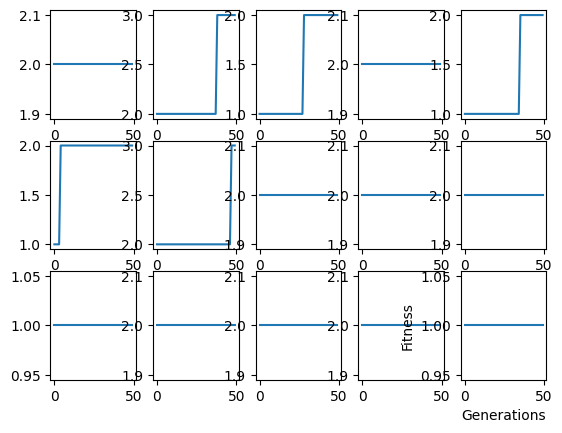

Input Variable: 1
No. Of Instructions: 10


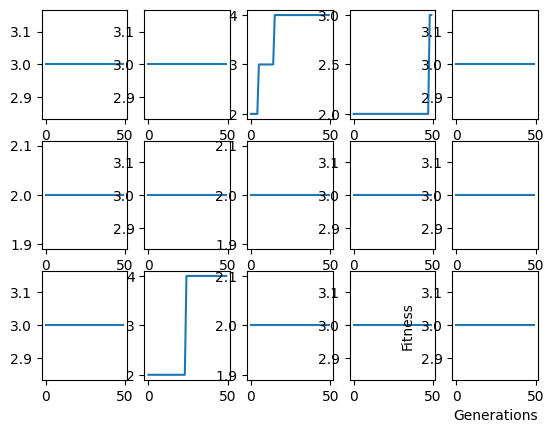

Input Variable: 1
No. Of Instructions: 20


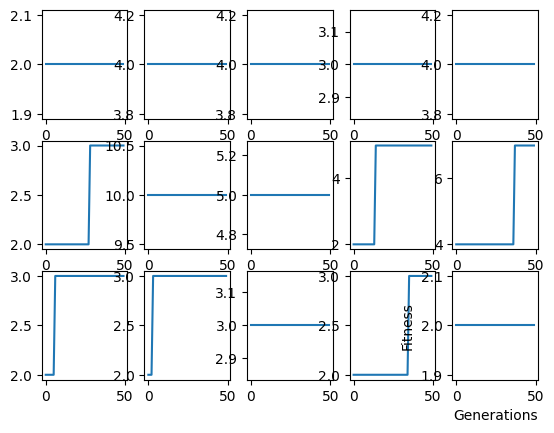

Input Variable: -1
No. Of Instructions: 5


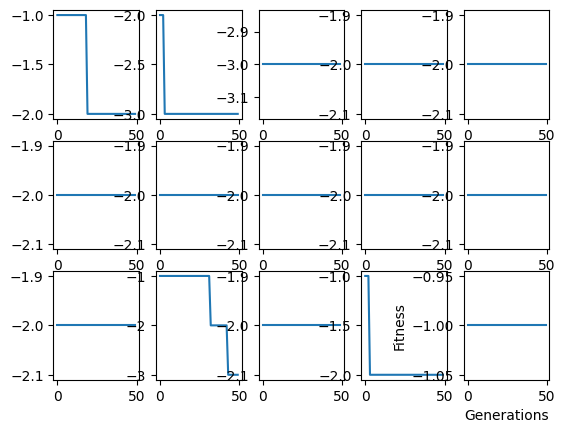

Input Variable: -1
No. Of Instructions: 10


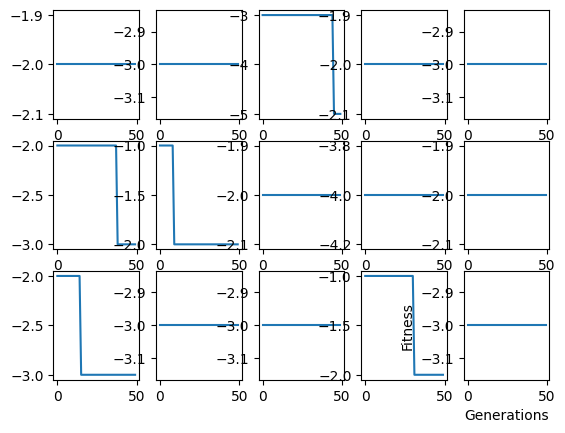

Input Variable: -1
No. Of Instructions: 20


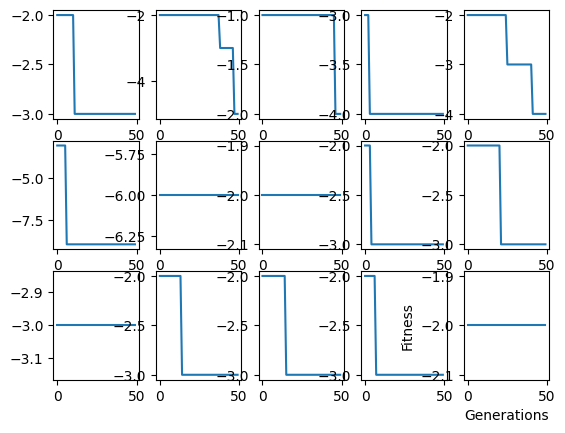

In [791]:
import matplotlib.pyplot as plt

inputs = [1, -1]

iterations = 15

byte_size = 3 # Bits
no_inst = 0 # No of Instructions

change = [5, 10, 20]
titles = ["No. Instructions: 5", "No. Instructions: 10", "No. Instructions: 20"]

generation_limit = 50

stats = []

for input_index in range(0, len(inputs)):

    per_input = []

    for inst_index in range(0, len(change)):

        no_inst = change[inst_index]
        program_output = []


        print("Input Variable: " + str(inputs[input_index]))
        print("No. Of Instructions: " + str(no_inst))

        for iteration in range(0, iterations):

            N = no_inst * byte_size  # Gene Length
            M = 50 # Population Size
            T = 100 # Tournament Size

            mutation_rate = 10/N
            crossover_rate = random.random()
            population = random_population(M, N)
            program = to_program(no_inst, byte_size)
            instructions = program_phenotype(program)
            fitness = execute_program(instructions, inputs[input_index])
            
            results = problem_1(inputs[input_index])

            plt.subplot(3, 5, iteration+1)
            plt.plot(results)

            program_output.append(results[len(results)-1])

        per_input.append(program_output)
            
        # plt.subplot(2, 1, 2)

        plt.xlabel("Generations")
        plt.ylabel("Fitness")
        plt.show()

    stats.append(per_input)




# REPORT #

Generating a scatter graph on each of the changes of instructions you can see there is quite a bit of varience between all the best values. The standard devation between all the points can confirm the varience

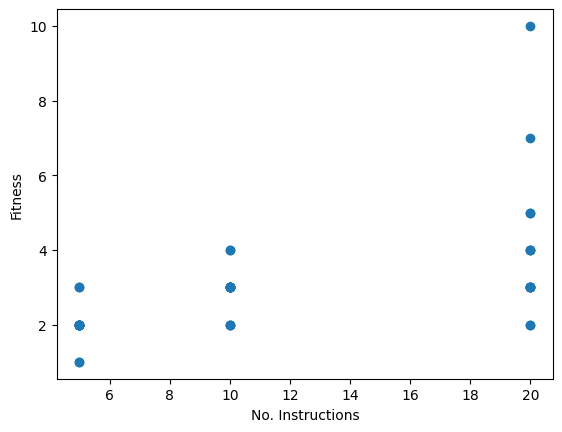

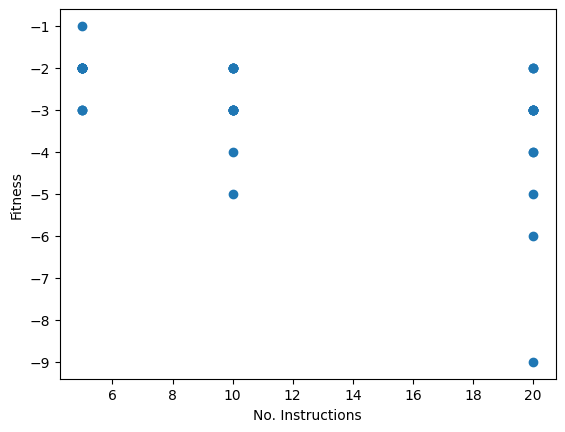

In [792]:
# print(stats)
for input_index in range(0, len(stats)): # SCATTER GRAPH
    x = []
    y = []
    for instr in range(0, len(stats[input_index])):
        for num in stats[input_index][instr]:
            x.append(change[instr])
            y.append(num)

    plt.scatter(x, y)
    plt.xlabel("No. Instructions")
    plt.ylabel("Fitness")
    plt.show()

In [793]:
import math

# https://www.google.com/search?q=how+to+calculate+standard+deviation&rlz=1C1CHBF_en-GBGB879GB879&oq=how+to+calculate+stand&gs_lcrp=EgZjaHJvbWUqCggAEAAYsQMYgAQyCggAEAAYsQMYgAQyBwgBEAAYgAQyBggCEEUYOTIHCAMQABiABDIHCAQQABiABDIHCAUQABiABDIHCAYQABiABDIHCAcQABiABDIHCAgQABiABDIHCAkQABiABNIBCDM4NzdqMGo3qAIAsAIA&sourceid=chrome&ie=UTF-8
def standard_deviation(data):
    mean = 0
    for num in data:
        mean += num
    mean = mean / len(data)

    divations = data[:]
    for div in range(0, len(divations)):
        divations[div] = (divations[div] - mean) ** 2

    sum = 0
    for div in divations:
        sum += div

    varience = sum / (len(divations) -1)

    return math.sqrt(varience)

for input_index in range(0, len(stats)):
    for instr in range(0, len(stats[input_index])):
        print("Input: " + str(inputs[input_index]))
        print("No. of Instructions: " + str(change[instr]))
        print(stats[input_index][instr])
        print("Standard Deviation: " + str(standard_deviation(stats[input_index][instr])))

Input: 1
No. of Instructions: 5
[2, 3, 2, 2, 2, 2, 3, 2, 2, 2, 1, 2, 2, 2, 1]
Standard Deviation: 0.5345224838248488
Input: 1
No. of Instructions: 10
[3, 3, 4, 3, 3, 2, 3, 2, 3, 3, 3, 4, 2, 3, 3]
Standard Deviation: 0.5936168397046636
Input: 1
No. of Instructions: 20
[2, 4, 4, 3, 4, 3, 10, 5, 5, 7, 3, 3, 3, 3, 2]
Standard Deviation: 2.0862360730226466
Input: -1
No. of Instructions: 5
[-2, -3, -3, -2, -2, -2, -2, -2, -2, -2, -2, -3, -2, -2, -1]
Standard Deviation: 0.5163977794943222
Input: -1
No. of Instructions: 10
[-2, -3, -5, -2, -3, -3, -2, -2, -4, -2, -3, -3, -3, -2, -3]
Standard Deviation: 0.8618916073713347
Input: -1
No. of Instructions: 20
[-3, -5, -2, -4, -4, -9, -6, -2, -3, -3, -3, -3, -3, -3, -2]
Standard Deviation: 1.8387366263150307


For each of these runs there was a population size of 50 and a tournment selections size of 100. Mutation rate was 10/N and crossover rate was 5/8. Looking back if I wanted to improve the algorithm then I could have dynamically changed the mutation and crossover rate to better suit the difference in instructions. Unfortunately I don't quite understand how changing the paramaters for the genetic algorithm changes the performace. I understand what changes ie the higher the population size then the more individuals it generates and higher tournament size means that more individuals will be picked which lowers the chance for "less" optimal solutions to carry over to the next generation. However, I do not know what values are best to limit the chances the genetic algorithm finds local maxima. Or to find paramaters that are good for searching the best solution. Because of this I mostly stuck to the same paramaters and so that is a big limitation in my program functionality

I'm not too sure what the best solution even is with the number of instructions that I've given it. However when I ran the ga by itself with a lot more generations it was able to find better solutions. During the 20 instruction run it was able to find a set of instructions that produced the outcome of 36 (shown in the markdown). This is no where even close to the values that my genetic algorithm is producing which further implies that it's getting stuck at local maxima.

## 3.2 Task 6 - Program Execution and Fitness Functions

### Problem 2

21


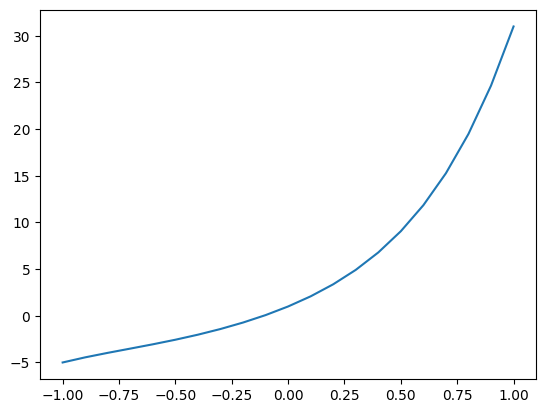

In [794]:
import matplotlib.pyplot as plt

x = [-1, -.9, -.8, -.7, -.6, -.5, -.4, -.3, -.2, -.1, 0, .1, .2, .3, .4, .5, .6, .7, .8, .9, 1]
print(len(x))

y = []

for num in x:
    y.append(2 * num**5 + 4 * num**4 + 6 * num**3 + 8 * num**2 + 10 * num + 1)

plt.plot(x, y)
plt.show()

---
### polynomial_fitness function

This is the fitness function that was used in problem 2. takes the program output and input index as inputs. the input index is the index of the value it's trying to compute. This function calculates how close the output is to the target value and returns it. 0 is a perfect match of output and target. there are no negative values

In [795]:
def polynomial_fitness(program_output, input_index):
    target = y[input_index]

    output = []

    for out in program_output:
        # Calc to how close it is
        if out > target:
            output.append(out - target)
        else:
            output.append(target - out)

    return output

input_index = 0

population = random_population(5, 5*3)
program = to_program(5, 3)
instructions = program_phenotype(program)
program_output = execute_program(instructions, x[input_index])
fitness = polynomial_fitness(program_output, input_index)


print("Input variable: " + str(x[input_index]))
print("Expected value: " + str(y[input_index]))
print("Population: " + str(population))
print("Output: " + str(program_output))
print("Fitness: " + str(fitness))

Input variable: -1
Expected value: -5
Population: [[1, 0, 0, 1, 1, 0, 0, 1, 0, 1, 0, 0, 0, 1, 1], [0, 1, 1, 1, 0, 1, 0, 1, 1, 1, 0, 1, 1, 0, 0], [1, 1, 0, 1, 0, 0, 1, 0, 1, 0, 1, 1, 0, 0, 0], [0, 0, 0, 1, 1, 0, 1, 0, 0, 1, 0, 1, 0, 0, 1], [1, 1, 0, 1, 1, 0, 0, 0, 1, 1, 1, 0, 0, 0, 0]]
Output: [-1, -1, -1, -1, 0]
Fitness: [4, 4, 4, 4, 5]


In [796]:
# Problem 2

def problem_2():

    global crossover_rate, population, program, instructions, program_output, fitness, best_fitness, best_outcome, best_instruction
    
    best_of_best = []

    for input_index in range(0, len(x)):

        input_variable = x[input_index]

        crossover_rate = random.random()
        population = random_population(M, N)
        program = to_program(no_inst, byte_size)
        instructions = program_phenotype(program)
        program_output = execute_program(instructions, input_variable)
        fitness = polynomial_fitness(program_output, input_index)

        best_fitness = 999
        best_outcome = None
        best_instruction = None

        for gen in range(0, generation_limit):
            offspring = None
            crossover_rate = random.random()

            index = neg_tournament(M, T)

            if crossover_rate < 1/2:
                offspring = mutate(index)
            else:
                offspring = crossover(index, neg_tournament(M, T))

            population[tournament(M, T)] = offspring
            program = to_program(no_inst, byte_size)
            instructions = program_phenotype(program)
            program_output = execute_program(instructions, input_variable)
            fitness = polynomial_fitness(program_output, input_index)


            # STORE BEST VALUES FOUND SO FAR
            best_index = best(fitness, -1) # -1 for best lowest score

            if fitness[best_index] < best_fitness:
                best_fitness = fitness[best_index]
                best_outcome = program_output[best_index]
                best_instruction = instructions[best_index]
                

            

            # print("======= Generation: " + str(gen) + " ==========")
            # print("Population: " + str(population))
            # print("Instructions: " + str(instructions))
            # print("Output: " + str(program_output))
            # print("Fitness: " + str(fitness))

        

        best_of_best.append(best_outcome)
        # print("============== BEST VALUES FOUND: ==============")
        # print("Exected Value: " + str(y[input_index]))
        # print("Best Outcome: " + str(best_outcome))
        # print("Fitness: " + str(best_fitness))
        # print("Best Instructions: " + str(best_instruction))

    # print(y)
    # print(best_of_best)
    return best_of_best

byte_size = 3 # Bits
no_inst = 21 # No of Instructions

N = no_inst * byte_size  # Gene Length
M = 100 # Population Size
T = 50 # Tournament Size

mutation_rate = 5/N
generation_limit = 50

crossover_rate = random.random()
population = random_population(M, N)
program = to_program(no_inst, byte_size)
instructions = program_phenotype(program)
program_output = execute_program(instructions, x[0])
fitness = polynomial_fitness(program_output, 0)

best_fitness = 999
best_outcome = None
best_instruction = None

problem_2()

[-5,
 -3.8,
 -3.8,
 -3.0,
 -3,
 -2.5,
 -1.7999999999999998,
 -1.3,
 -1,
 0.11000000000000001,
 1,
 2.1,
 3.6000000000000005,
 3.7,
 2.4,
 4.5,
 4,
 4.7,
 5,
 4,
 5]

## 3.2 Task 7 - Experiments and Analysis of Results

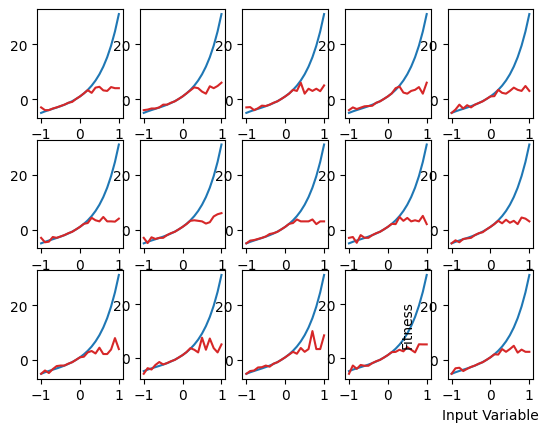

In [797]:
import matplotlib.pyplot as plt

iterations = 15

byte_size = 3 # Bits
no_inst = 21 # No of Instructions

generation_limit = 50

stats = []

for iteration in range(0, iterations):

    N = no_inst * byte_size  # Gene Length
    M = 100 # Population Size
    T = 50 # Tournament Size

    crossover_rate = random.random()
    population = random_population(M, N)
    program = to_program(no_inst, byte_size)
    instructions = program_phenotype(program)
    program_output = execute_program(instructions, x[0])
    fitness = polynomial_fitness(program_output, 0)

    best_fitness = 999
    best_outcome = None
    best_instruction = None
    
    results = problem_2()

    stats.append(results)

    plt.subplot(3, 5, iteration+1)

    plt.plot(x, y, color="tab:blue")
    plt.plot(x, results, color="tab:red")

plt.xlabel("Input Variable")
plt.ylabel("Fitness")
plt.show()

# https://matplotlib.org/stable/gallery/subplots_axes_and_figures/two_scales.html
# https://matplotlib.org/stable/gallery/subplots_axes_and_figures/shared_axis_demo.html



## Report

As shown in the graphs above the ga was pretty successful in finding the smaller values. However when the program input is around 0.1 onwards then the ga struggles to come up with a solution that is good enough. I know that the ga is able to find these values because I ran a search with many more generations and was able to find solutions that matched the expected values. This is most likely because of local maxima which with a low generation limit struggles to overcome this. Like with the first problem there is a lot of variation in the solutions given. Here is a scatter of all the values and their inputs as well as the standard deviation between all generated solutions.

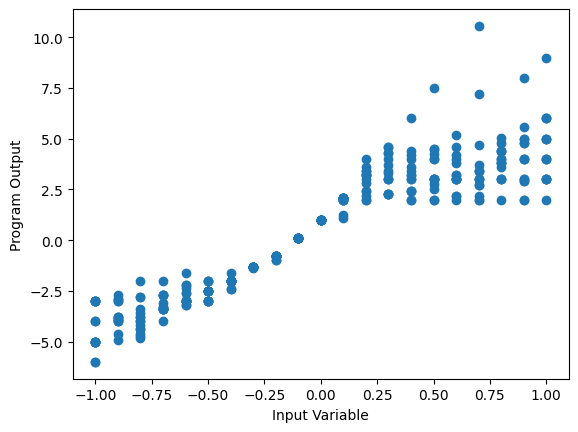

In [801]:
x_axis = []
y_axis = []

for perm in stats:
    for num in range(0, len(perm)):
        y_axis.append(perm[num])
        x_axis.append(x[num])

plt.scatter(x_axis, y_axis)
plt.xlabel("Input Variable")
plt.ylabel("Program Output")
plt.show()

In [802]:
sorted_stats = [[], [], [], [], [], [], [], [], [], [], [], [], [], [], [], [], [], [], [], [], []]

def mean(data):
    sum = 0
    for num in data:
        sum += num
    return sum/len(data)

for perm in stats:
    for num in range(0, len(perm)):
        sorted_stats[num].append(perm[num])

difference = []

for x_input in range(0, len(x)):
    print("==== Input Variable: " + str(x[x_input]) + " ====")
    print("Expected Output: " + str(y[x_input]))
    print("Mean Output: " + str(mean(sorted_stats[x_input])))
    print("Standard Deviation: " + str(standard_deviation(sorted_stats[x_input])))
    diff = y[x_input] - mean(sorted_stats[x_input])
    print("Difference between mean & expected: " + str(diff))
    difference.append(diff)
    print("")

==== Input Variable: -1 ====
Expected Output: -5
Mean Output: -4.333333333333333
Standard Deviation: 1.1126972805283735
Difference between mean & expected: -0.666666666666667

==== Input Variable: -0.9 ====
Expected Output: -4.45058
Mean Output: -3.6806666666666663
Standard Deviation: 0.6493124568854864
Difference between mean & expected: -0.7699133333333341

==== Input Variable: -0.8 ====
Expected Output: -3.96896
Mean Output: -3.8186666666666658
Standard Deviation: 0.7951088574768208
Difference between mean & expected: -0.15029333333333428

==== Input Variable: -0.7 ====
Expected Output: -3.5137400000000003
Mean Output: -3.126666666666667
Standard Deviation: 0.4832430129073876
Difference between mean & expected: -0.3870733333333334

==== Input Variable: -0.6 ====
Expected Output: -3.05312
Mean Output: -2.728
Standard Deviation: 0.458369782100497
Difference between mean & expected: -0.32511999999999963

==== Input Variable: -0.5 ====
Expected Output: -2.5625
Mean Output: -2.5666666666

Here I've calculated the difference between the solution that the ga gave vs what it was expected to give. If the GA was perfect then these bars would be flat with each other. However, any input value above 0.1 can see a dramatic increase in difference. 

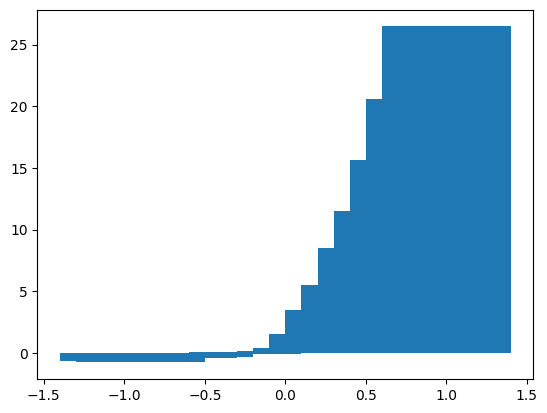

In [800]:
plt.bar(x, difference)
plt.show()

Again the right solutions are out there however, my ga was unable to find them in the limitations given. Maybe the ga input paramaters could have been changed to produce a better output but I struggle to see the change when I change these values myself. I found that the current configuration gives the best results but it could be very wrong. 